## **Interestingness Measures**

*Support* and *confidence* are not enough: a rule can be frequent and reliable and still be **meaningless** ( `anything ⇒ milk` when everybody buys milk ). This notebook compares **16 measures** computed from the same 2×2 contingency table, shows which of them agree, demonstrates **null-invariance** and ends with the question that is usually forgotten: *is the association **statistically significant** after correcting for the thousands of rules that were tested?*

**Notebooks of this series:** 1. Apriori · 2. FP-Growth · 3. Eclat · 4. Comparing the Algorithms · 5. Association Rules ( Generation, Reduction and Evaluation ) · 6. Interestingness Measures · 7. Sequential Patterns ( SPADE ) · 8. High-Utility Itemsets · 9. Associative Classification ( CBA )

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Dataset: Simulated Retail Baskets**

6 000 baskets generated from **shopper profiles** (breakfast, party, family dinner, baby, healthy), so that natural associations appear, a mild unexpected one (*diapers ⟶ beer*) and a **loyalty-card bundle** (diapers always come with the baby club card).

In [4]:
#Generate the Transactions ( Shopper Profiles + Random Background Items )
rng = np.random.default_rng(RANDOM_STATE)
profiles = {
    "breakfast":     {"bread": .70, "butter": .50, "jam": .35, "milk": .60, "coffee": .50, "sugar": .30, "eggs": .40, "cereal": .30},
    "party":         {"beer": .60, "chips": .60, "soda": .50, "pizza": .35, "ice": .30, "peanuts": .30},
    "family dinner": {"pasta": .60, "tomato_sauce": .50, "cheese": .40, "chicken": .40, "rice": .40, "beans": .30, "salad": .30, "tomato": .30},
    "baby":          {"diapers": .80, "baby_food": .50, "wipes": .50, "milk": .40, "beer": .25},
    "healthy":       {"salad": .60, "fruit": .70, "yogurt": .50, "fish": .40, "lemon": .30, "water": .60, "tomato": .30},
}
items = sorted({i for p in profiles.values() for i in p} | {"baby_club_card"})

def make_basket():
    chosen = rng.choice(list(profiles), size=1 if rng.random() < 0.75 else 2, replace=False)
    basket = {i for p in chosen for i, prob in profiles[p].items() if rng.random() < prob}
    basket |= {i for i in items if rng.random() < 0.025}                      # random background items
    if "diapers" in basket:
        basket.add("baby_club_card")                                           # loyalty-card bundle (always together)
    return frozenset(basket) if basket else frozenset([str(rng.choice(items))])

transactions = [make_basket() for _ in range(6000)]
print("transactions:", len(transactions), "| distinct items:", len(items), "| mean basket size:", round(np.mean([len(t) for t in transactions]), 2))
for t in transactions[:3]:
    print("  ", sorted(t))

transactions: 6000 | distinct items: 31 | mean basket size: 4.72
   ['beans', 'fruit', 'pasta', 'tomato', 'water']
   ['fruit', 'salad', 'tomato_sauce']
   ['fish', 'fruit', 'salad', 'yogurt']


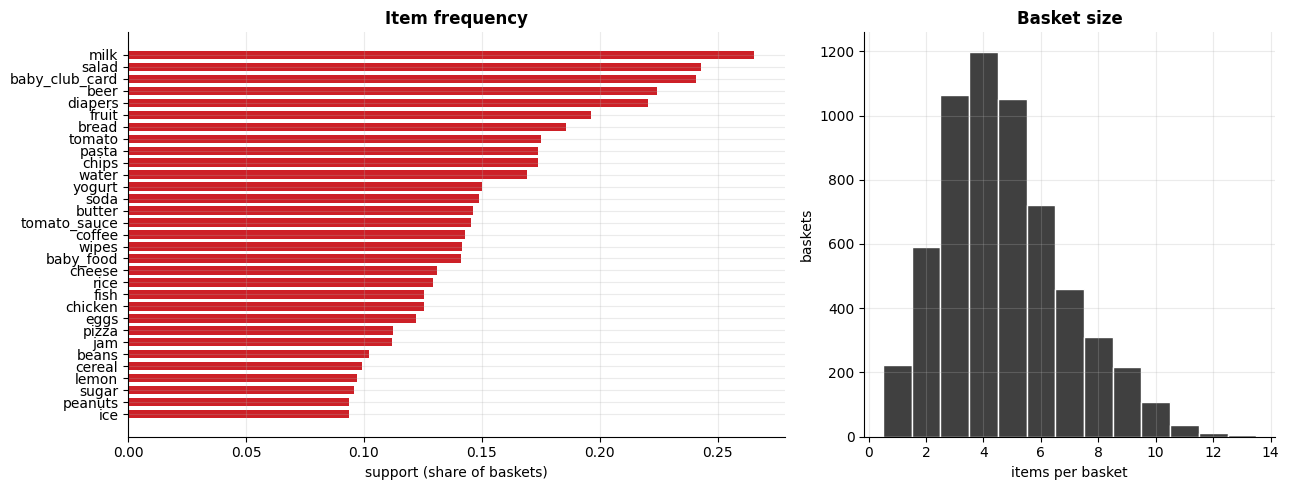

In [5]:
#Explore the Data ( Item Frequency and Basket Size )
freq_items = pd.Series({i: sum(i in t for t in transactions) / len(transactions) for i in items}).sort_values()
sizes = pd.Series([len(t) for t in transactions])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].barh(freq_items.index, freq_items.values, color=RED, height=0.7); axes[0].set_xlabel("support (share of baskets)"); axes[0].set_title("Item frequency")
axes[1].hist(sizes, bins=range(1, sizes.max() + 2), color=DARK, edgecolor="white", align="left"); axes[1].set_xlabel("items per basket"); axes[1].set_ylabel("baskets"); axes[1].set_title("Basket size")
plt.tight_layout(); plt.show()

### **2. Rule Metrics**

For a rule $A \Rightarrow B$ (all supports are shares of the baskets):

| Metric | Formula | Reading |
|---|---|---|
| **Support** | $P(A \cap B)$ | how frequent |
| **Confidence** | $P(B \mid A)$ | how reliable |
| **Lift** | $\dfrac{P(B \mid A)}{P(B)}$ | $>1$ positive · $=1$ independent · $<1$ negative |
| **Leverage** | $P(A \cap B) - P(A)P(B)$ | excess co-occurrence over independence |
| **Conviction** | $\dfrac{1 - P(B)}{1 - \text{conf}}$ | how much $A$ without $B$ is *unexpected* ($\infty$ if conf = 1) |
| **Zhang's** | $\dfrac{\text{leverage}}{\max\{P(AB)(1-P(A)),\ P(A)(P(B)-P(AB))\}}$ | association from −1 to +1 |

In [6]:
#Bit-Set Representation ( One Integer per Item = Its Transaction List ) and Rule-Metric Function
from itertools import combinations
from collections import Counter, defaultdict
import time

def build_tidsets(transactions):
    tid = defaultdict(int)
    for t_idx, basket in enumerate(transactions):
        bit = 1 << t_idx
        for item in basket:
            tid[item] |= bit
    return dict(tid)

def rule_metrics(s_a, s_b, s_ab):
    conf = s_ab / s_a
    lev = s_ab - s_a * s_b
    denom = max(s_ab * (1 - s_a), s_a * (s_b - s_ab))
    return {"support": s_ab, "confidence": conf, "lift": conf / s_b, "leverage": lev,
            "conviction": (1 - s_b) / (1 - conf) if conf < 1 else np.inf, "zhangs": lev / denom if denom > 0 else 0.0}

tid_all = build_tidsets(transactions)
N = len(transactions)
print("support(beer) =", tid_all["beer"].bit_count() / N, "| support(diapers) =", tid_all["diapers"].bit_count() / N)
for a, b in [("diapers", "beer"), ("diapers", "baby_club_card")]:
    print(f"rule {a} => {b}:", {k: round(v, 3) for k, v in rule_metrics(tid_all[a].bit_count() / N, tid_all[b].bit_count() / N, (tid_all[a] & tid_all[b]).bit_count() / N).items()})

support(beer) = 0.22433333333333333 | support(diapers) = 0.22033333333333333
rule diapers => beer: {'support': 0.066, 'confidence': 0.301, 'lift': 1.342, 'leverage': 0.017, 'conviction': 1.11, 'zhangs': 0.327}
rule diapers => baby_club_card: {'support': 0.22, 'confidence': 1.0, 'lift': 4.152, 'leverage': 0.167, 'conviction': inf, 'zhangs': 0.974}


### **3. One Table, Many Measures**

Every rule $A \Rightarrow B$ is summarized by a **2×2 contingency table** of baskets:

| | **B** | **not B** |
|---|---|---|
| **A** | $a$ | $b$ |
| **not A** | $c$ | $d$ |

| Measure | Formula | Reading |
|---|---|---|
| Support · Confidence · Lift · Leverage · Conviction · Zhang's | see section 2 | classic measures |
| **Phi** ( correlation ) | $\dfrac{ad-bc}{\sqrt{(a+b)(c+d)(a+c)(b+d)}}$ | −1 to +1 |
| **Yule's Q** | $\dfrac{ad-bc}{ad+bc}$ | −1 to +1, from the odds ratio |
| **Odds ratio** | $\dfrac{ad}{bc}$ | $>1$ positive association |
| **Jaccard** | $\dfrac{a}{a+b+c}$ | overlap of the two sets of baskets |
| **Cosine** | $\dfrac{a}{\sqrt{(a+b)(a+c)}}$ | geometric mean of $P(B \mid A)$ and $P(A \mid B)$ |
| **Kulczynski** | $\tfrac12\left[P(B \mid A)+P(A \mid B)\right]$ | average of both confidences |
| **All-confidence** | $\dfrac{a}{\max(a+b,\ a+c)}$ | the *worst* of both confidences |
| **Certainty factor** | $\dfrac{\text{conf}-P(B)}{1-P(B)}$ | gain in certainty about $B$ |
| **Imbalance ratio** | $\dfrac{|b-c|}{a+b+c}$ | 0 = balanced, 1 = totally unbalanced |
| **Chi-square** | $\dfrac{n(ad-bc)^2}{(a+b)(c+d)(a+c)(b+d)}$ | distance from independence |

A measure is **null-invariant** when it does not change if baskets that contain **neither** A nor B ( the *null transactions*, the cell $d$ ) are added.

In [ ]:
#Contingency Table of Every Ordered Pair of Items ( a, b, c and d )
B_mat = np.array([[i in t for i in items] for t in transactions], dtype=float)
co = B_mat.T @ B_mat                                        # co[x, y] = number of baskets with items x and y
count = np.diag(co).copy()
rows = []
for x, A in enumerate(items):
    for y, B in enumerate(items):
        if x != y:
            a = co[x, y]; b = count[x] - a; c = count[y] - a
            rows.append((A, B, a, b, c, N - a - b - c))
cont = pd.DataFrame(rows, columns=["A", "B", "a", "b", "c", "d"])
cont.head()

In [ ]:
#Function with All the Measures ( Works with Numbers or Arrays )
def measures(a, b, c, d):
    a, b, c, d = (np.asarray(v, dtype=float) for v in (a, b, c, d))
    n = a + b + c + d
    p_ab, p_a, p_b = a / n, (a + b) / n, (a + c) / n
    with np.errstate(divide="ignore", invalid="ignore"):
        conf = a / (a + b)                                   # P(B | A)
        conf_rev = a / (a + c)                               # P(A | B)
        leverage = p_ab - p_a * p_b
        denom = np.maximum(p_ab * (1 - p_a), p_a * (p_b - p_ab))
        return {
            "support": p_ab,
            "confidence": conf,
            "lift": p_ab / (p_a * p_b),
            "leverage": leverage,
            "conviction": np.where(conf < 1, (1 - p_b) / (1 - conf), np.inf),
            "zhangs": np.where(denom > 0, leverage / denom, 0.0),
            "phi": (a * d - b * c) / np.sqrt((a + b) * (c + d) * (a + c) * (b + d)),
            "yules_q": (a * d - b * c) / (a * d + b * c),
            "odds_ratio": np.where(b * c > 0, (a * d) / (b * c), np.inf),
            "jaccard": a / (a + b + c),
            "cosine": a / np.sqrt((a + b) * (a + c)),
            "kulczynski": 0.5 * (conf + conf_rev),
            "all_confidence": a / np.maximum(a + b, a + c),
            "certainty_factor": np.where(conf >= p_b, (conf - p_b) / (1 - p_b), (conf - p_b) / p_b),
            "imbalance_ratio": np.abs(b - c) / (a + b + c),
            "chi_square": n * (a * d - b * c) ** 2 / ((a + b) * (c + d) * (a + c) * (b + d)),
        }

pairs = cont[["A", "B"]].join(pd.DataFrame(measures(cont["a"], cont["b"], cont["c"], cont["d"])))
pairs["rule"] = pairs["A"] + " => " + pairs["B"]

# Quality control: the vectorized measures must match the rule_metrics() function of the notebook
sample = pairs.sample(50, random_state=RANDOM_STATE)
reference = pd.DataFrame([rule_metrics(tid_all[r.A].bit_count() / N, tid_all[r.B].bit_count() / N, (tid_all[r.A] & tid_all[r.B]).bit_count() / N) for r in sample.itertuples()], index=sample.index)
print("pairs:", len(pairs), "| max difference to rule_metrics() on 50 random rules:", float(np.nanmax(np.abs((sample[["support", "confidence", "lift", "leverage", "zhangs"]] - reference[["support", "confidence", "lift", "leverage", "zhangs"]]).to_numpy()))))

In [ ]:
#The Same Rule, Many Opinions ( Five Well-Known Pairs )
known = ["diapers => beer", "diapers => baby_club_card", "bread => butter", "beer => chips", "milk => coffee"]
pairs.set_index("rule").loc[known].drop(columns=["A", "B"]).T.round(3)

### **4. Comparing the Measures**

In [ ]:
#Do the Measures Agree? ( Spearman Rank Correlation across All the Pairs )
metric_cols = ["support", "confidence", "lift", "leverage", "conviction", "zhangs", "phi", "yules_q", "odds_ratio", "jaccard", "cosine", "kulczynski", "all_confidence", "certainty_factor"]
rank_corr = pairs[metric_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(rank_corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(metric_cols))); ax.set_xticklabels(metric_cols, rotation=90); ax.set_yticks(range(len(metric_cols))); ax.set_yticklabels(metric_cols)
annotate_heatmap(ax, rank_corr, "{:.1f}"); fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman correlation"); ax.set_title("Agreement between the rankings of the measures")
plt.show()

In [ ]:
#Top Rules by Different Measures ( Pairs with Support ≥ 1% ): Each Measure Likes Different Rules
eligible = pairs[pairs["support"] >= 0.01]
pd.DataFrame({m: eligible.sort_values(m, ascending=False)["rule"].head(6).to_numpy() for m in ["lift", "leverage", "kulczynski", "all_confidence"]})

In [ ]:
#Null-Invariance: Add Baskets that Contain Neither Item ( A = diapers, B = beer )
row = cont[(cont["A"] == "diapers") & (cont["B"] == "beer")].iloc[0]
a0, b0, c0, d0 = (float(row[k]) for k in "abcd")
extra = np.array([0, 1_000, 5_000, 20_000, 100_000, 1_000_000], dtype=float)
nulls = pd.DataFrame(measures(np.full(len(extra), a0), np.full(len(extra), b0), np.full(len(extra), c0), d0 + extra), index=extra.astype(int))
nulls.index.name = "extra null baskets"

compare_cols = ["confidence", "lift", "leverage", "zhangs", "phi", "kulczynski", "cosine", "jaccard", "all_confidence"]
invariant = {m: bool(np.allclose(nulls[m], nulls[m].iloc[0])) for m in compare_cols}
print("null-invariant measures:", [m for m, ok in invariant.items() if ok])
print("changed by the null baskets:", [m for m, ok in invariant.items() if not ok])

fig, ax = plt.subplots(figsize=(8, 4))
for m in compare_cols:
    ax.plot(range(len(extra)), nulls[m] / nulls[m].iloc[0], marker="o", lw=2.2 if invariant[m] else 1.2, ls="-" if invariant[m] else "--", label=m)
ax.set_xticks(range(len(extra))); ax.set_xticklabels([f"{int(e):,}" for e in extra], rotation=20); ax.set_xlabel("extra baskets with neither item"); ax.set_ylabel("value / value without extra baskets")
ax.set_yscale("log"); ax.set_title("Null-invariance"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
nulls[compare_cols].round(3)

In [ ]:
#Imbalance Ratio: Pairs where One Item Is Much More Frequent than the Other ( Kulczynski > 0.3 )
unordered = pairs[pairs["A"] < pairs["B"]]
unordered[unordered["kulczynski"] > 0.3].sort_values("imbalance_ratio", ascending=False)[["A", "B", "support", "confidence", "kulczynski", "imbalance_ratio", "lift"]].head(6).round(3)

### **5. Statistical Significance ( Are the Associations Real or Noise? )**

Mining tests **hundreds or thousands of rules at once**. At a 5% significance level, about 1 in 20 *unrelated* pairs will look significant by chance. Two defenses:

* **Multiple-testing correction:** Bonferroni ( very strict ) or **Benjamini–Hochberg** ( controls the false discovery rate, FDR )
* **Effect size:** with many baskets even a tiny association is *significant*; keep only the rules with a relevant measure ( lift, phi ... ) too

To see this, the same test is applied to the real baskets and to a **shuffled copy** in which every item is permuted independently ( by construction: no association at all ).

In [ ]:
#P-Values for Every Unordered Pair ( Fisher's Exact Test ) and the Benjamini-Hochberg Correction
from scipy.stats import fisher_exact

def pair_table(B):
    co_, cnt = B.T @ B, np.diag(B.T @ B)
    rows = []
    for x in range(B.shape[1]):
        for y in range(x + 1, B.shape[1]):
            a_ = co_[x, y]; b_ = cnt[x] - a_; c_ = cnt[y] - a_; d_ = B.shape[0] - a_ - b_ - c_
            rows.append((items[x], items[y], a_, b_, c_, d_, fisher_exact([[a_, b_], [c_, d_]])[1]))
    return pd.DataFrame(rows, columns=["A", "B", "a", "b", "c", "d", "p_value"])

def benjamini_hochberg(p, q=0.05):
    p = np.asarray(p); order = np.argsort(p); m = len(p)
    passed = p[order] <= q * np.arange(1, m + 1) / m
    k = np.max(np.where(passed)[0]) + 1 if passed.any() else 0
    reject = np.zeros(m, dtype=bool); reject[order[:k]] = True
    return reject

shuffled = np.random.default_rng(RANDOM_STATE).permuted(B_mat, axis=0)        # every item permuted independently: no association at all
tests = {"real baskets": pair_table(B_mat), "shuffled baskets ( no association )": pair_table(shuffled)}
summary = {}
for name, t in tests.items():
    m = len(t)
    summary[name] = {"pairs tested": m, "significant ( p < 0.05, no correction )": int((t["p_value"] < 0.05).sum()),
                     "significant after Bonferroni": int((t["p_value"] < 0.05 / m).sum()), "significant after Benjamini-Hochberg ( FDR 5% )": int(benjamini_hochberg(t["p_value"]).sum())}
pd.DataFrame(summary)

In [ ]:
#Volcano Plot: Effect Size ( log2 Lift ) vs Evidence ( -log10 p-value ) with the Benjamini-Hochberg Decision
real = tests["real baskets"].copy()
real["lift"] = measures(real["a"], real["b"], real["c"], real["d"])["lift"]
real["significant"] = benjamini_hochberg(real["p_value"])
real["negligible effect"] = (real["lift"] - 1).abs() < 0.1

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(np.log2(real["lift"]), -np.log10(real["p_value"].clip(lower=1e-300)), c=np.where(real["significant"], RED, LIGHT), s=18, edgecolor=GRAY, lw=0.2)
ax.axvline(0, color=GRAY, ls="--"); ax.set_xlabel("log2(lift)  ( 0 = independence )"); ax.set_ylabel("-log10( p-value )"); ax.set_title("Significant pairs ( red ) after the FDR correction")
plt.tight_layout(); plt.show()
print("significant pairs with a negligible effect ( |lift - 1| < 0.1 ):", int((real["significant"] & real["negligible effect"]).sum()), "of", int(real["significant"].sum()))

### **6. Which Measure for Which Question?**

| Question | Use |
|---|---|
| Is the rule frequent enough to matter? | **support** |
| How reliable is the prediction? | **confidence** ( always together with lift ) |
| Is the co-occurrence above chance? | **lift**, **leverage**, **chi-square** |
| How strong and in which direction? | **Zhang's**, **phi**, **Yule's Q** |
| Do I have many baskets without both items? ( large and sparse data ) | **null-invariant** measures: **Kulczynski**, **cosine**, **Jaccard**, **all-confidence** |
| Are the two items very different in popularity? | **imbalance ratio** together with Kulczynski |
| Is the association real or noise? | **p-value with FDR correction** + an **effect size** |

**Never rank by a single measure:** lift loves rare items, confidence loves popular consequents and the p-value loves large samples.